In [4]:
import math

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")

Imports successful


In [11]:
csv = pd.read_csv('chessData_formatted.csv')

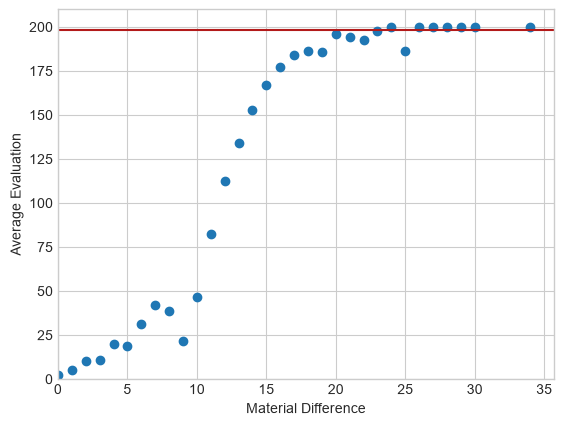

In [12]:
materialDiff = np.abs(csv['material_diff'])
evaluations = np.abs(csv['Evaluation']) / 100
evaluations = np.clip(evaluations, 0, 200)

# plt.scatter(materialDiff,evaluations)
# plt.xlabel('Material Difference')
# plt.ylabel('Evaluations')
# plt.show()

df = pd.DataFrame({
    'materialDiff': materialDiff,
    'evaluations': evaluations
})
# Average evaluation for each material difference
grouped = df.groupby('materialDiff')['evaluations'].mean()

# x = np.abs(grouped.index.to_numpy())
# y = np.abs(grouped.values)
x = grouped.index
y = grouped.values

plt.scatter(x,y)
plt.xlabel('Material Difference')
plt.ylabel('Average Evaluation')
plt.xlim(0)
plt.ylim(0)
plt.axhline(y=198, color=(0.7, 0.1, 0.1), linestyle='-')
plt.show()

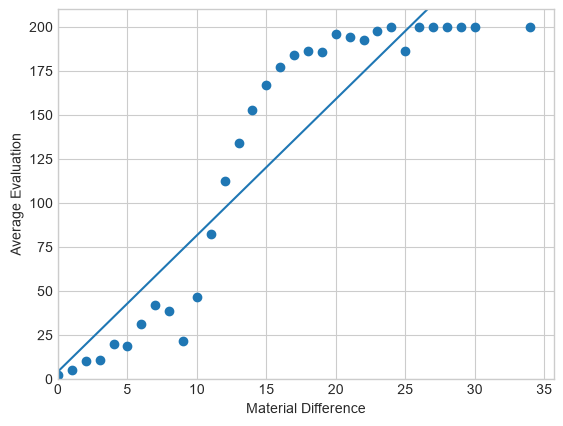

In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)

xnumpy = x.to_numpy()

model.fit(xnumpy[:, np.newaxis], y)

xfit = np.linspace(0, x.max())
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(x,y)
plt.xlabel('Material Difference')
plt.ylabel('Average Evaluation')
plt.xlim(0)
plt.ylim(0)
plt.plot(xfit, yfit)
plt.show()

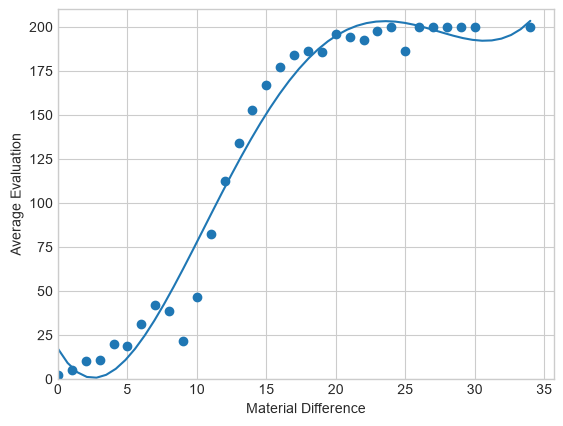

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

poly = PolynomialFeatures(3, include_bias=False)

poly_model = make_pipeline(PolynomialFeatures(4),
                           LinearRegression())

poly_model.fit(xnumpy[:, np.newaxis], y)

xfit = np.linspace(x.min() * 0.9, x.max())
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(x,y)
plt.xlabel('Material Difference')
plt.ylabel('Average Evaluation')
plt.xlim(0)
plt.ylim(0)
plt.plot(xfit, yfit)
plt.show()

In [15]:
# csv = pd.read_csv('chessData_formatted.csv', nrows=1000000)

evaluations = np.abs(csv['Evaluation'])

eval_ranges = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]
for e in evaluations:
    eval_ranges[int(e / 1000)] += 1

r = 0
for er in eval_ranges:
    print(str(r)+'-'+str(r+1000)+': '+str(er))
    r += 1000

total_count = 0
for er in eval_ranges:
    total_count += er

culled_count = 0
for i in range(6,18):
    culled_count += eval_ranges[i]

percentage = culled_count / total_count * 100
print("Total elements: ",total_count)
print("Removed elements: ",culled_count)
print("Removed percentage: ", percentage)

0-1000: 12181990
1000-2000: 345837
2000-3000: 45498
3000-4000: 6434
4000-5000: 22416
5000-6000: 93057
6000-7000: 60686
7000-8000: 11354
8000-9000: 569
9000-10000: 21
10000-11000: 0
11000-12000: 0
12000-13000: 0
13000-14000: 0
14000-15000: 12
15000-16000: 7
16000-17000: 0
17000-18000: 0
18000-19000: 0
19000-20000: 184035
20000-21000: 6119
Total elements:  12958035
Removed elements:  72649
Removed percentage:  0.5606482773043907


In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class GaussianFeatures(BaseEstimator, TransformerMixin):
    """Uniformly spaced Gaussian features for one-dimensional input"""

    def __init__(self, N, width_factor=2.0):
        self.N = N
        self.width_factor = width_factor

    @staticmethod
    def _gauss_basis(x, y, width, axis=None):
        arg = (x - y) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))

    def fit(self, X, y=None):
        # create N centers spread along the data range
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self

    def transform(self, X):
        return self._gauss_basis(X[:, :, np.newaxis], self.centers_,
                                 self.width_, axis=1)

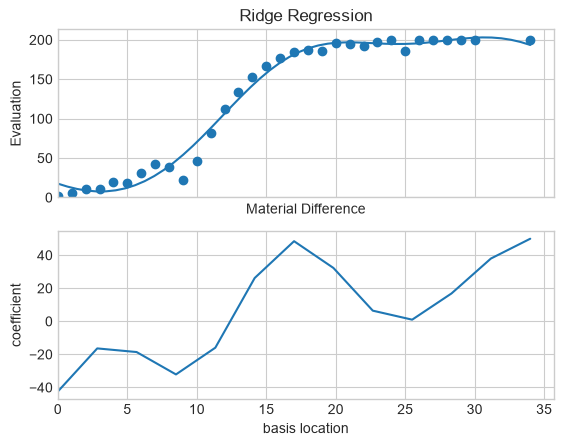

In [29]:
from sklearn.linear_model import Ridge

def basis_plot(model, title=None):
    fig, ax = plt.subplots(2, sharex=True)
    model.fit(xnumpy[:, np.newaxis], y)
    ax[0].scatter(x, y)
    ax[0].plot(xfit, model.predict(xfit[:, np.newaxis]))
    ax[0].set(xlabel='Material Difference', ylabel='Evaluation', ylim=0)

    if title:
        ax[0].set_title(title)

    ax[1].plot(model.steps[0][1].centers_,
               model.steps[1][1].coef_)
    ax[1].set(xlabel='basis location',
              ylabel='coefficient',
              xlim=0)

model = make_pipeline(GaussianFeatures(13), Ridge(alpha=0.1))
basis_plot(model, title='Ridge Regression')

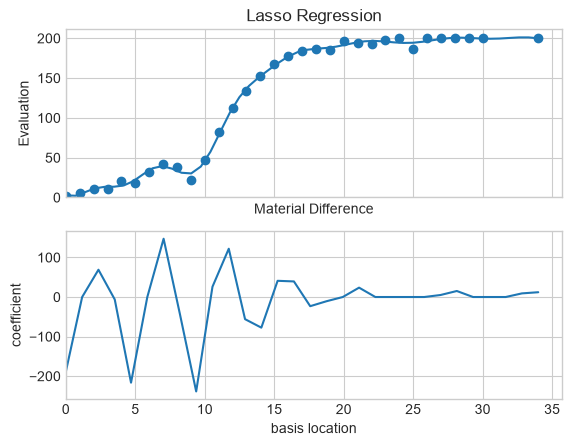

In [35]:
from sklearn.linear_model import Lasso
model = make_pipeline(GaussianFeatures(30), Lasso(alpha=0.001, max_iter=20000))
basis_plot(model, title='Lasso Regression')